# **Notebook 5: Solution V1 — RAG Evaluation**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./chroma_db/` — Created by Notebook 4
- [ ] `df_test.csv` — Created by Notebook 2
- [ ] `outputs.json` — Created by Notebooks 3+4
- [ ] GPU runtime enabled

**Files this notebook will CREATE:**
- [ ] `v1_metrics.csv` — Per-row Baseline vs V1 scores _(Evidence for comparative analysis)_

---

### **Task 3.3: Evaluate Solution V1**

> This task is split into five measurements (3.3.1–3.3.5). Run the shared setup cell below first (it loads the model, ChromaDB, and test data), then work through each measurement.

**── Shared setup ──**
Load the base model, reload ChromaDB (same embedding model as NB4), and load `df_test.csv` + `outputs.json`. Define helper functions `generate_baseline()` and `generate_naive_rag()` here so every subtask below can reuse them.

In [1]:
%pip install -q -U bitsandbytes accelerate langchain-huggingface langchain-chroma chromadb sentence-transformers rouge-score nltk

import os, re, glob, json, time, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from rouge_score import rouge_scorer
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/hybrid_rag')
SEED = 42
torch.manual_seed(SEED)

with open('outputs.json') as f:
    outputs = json.load(f)
with open('intent_sop_map.json') as f:
    intent_sop_map = json.load(f)
GEN_KWARGS = outputs['gen_kwargs']
RAG_PROMPT = outputs['rag_config']['rag_prompt']
TOP_K = outputs['rag_config']['top_k']

df_test = pd.read_csv('df_test.csv', keep_default_na=False, na_values=[''])
df_test['reference_sop'] = df_test['intent'].map(lambda i: intent_sop_map[i]['sop_file'])
sop_text = {os.path.basename(f): open(f, encoding='utf-8').read() for f in glob.glob('corporate_policies/*.md')}
print(len(df_test), 'test rows')

LOCAL_DB = '/tmp/chroma_db'   # work on a local copy, SQLite and the Drive mount don't get along
shutil.rmtree(LOCAL_DB, ignore_errors=True)
shutil.copytree('chroma_db', LOCAL_DB)
embeddings = HuggingFaceEmbeddings(model_name=outputs['rag_config']['embed_model'], encode_kwargs={'normalize_embeddings': True})
vector_db = Chroma(collection_name='sop_policies', embedding_function=embeddings, persist_directory=LOCAL_DB)
assert vector_db._collection.count() == outputs['rag_config']['n_chunks']

bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                                bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
tokenizer = AutoTokenizer.from_pretrained(outputs['model_id'])
tokenizer.padding_side = 'left'
model = AutoModelForCausalLM.from_pretrained(outputs['model_id'], quantization_config=bnb_config, device_map='auto')
model.eval()

@torch.no_grad()
def generate(messages_list, batch_size=16):
    replies = []
    for i in range(0, len(messages_list), batch_size):
        prompts = [tokenizer.apply_chat_template(m, tokenize=False, add_generation_prompt=True)
                   for m in messages_list[i:i + batch_size]]
        batch = tokenizer(prompts, return_tensors='pt', padding=True).to(model.device)
        out = model.generate(**batch, **GEN_KWARGS, pad_token_id=tokenizer.pad_token_id)
        replies += tokenizer.batch_decode(out[:, batch['input_ids'].shape[1]:], skip_special_tokens=True)
    return [r.strip() for r in replies]

def generate_baseline(queries):
    return generate([[{'role': 'system', 'content': outputs['baseline_prompt']}, {'role': 'user', 'content': q}]
                     for q in queries])

def generate_naive_rag(queries):
    hits = [vector_db.similarity_search(q, k=TOP_K) for q in queries]
    msgs = [[{'role': 'system', 'content': RAG_PROMPT.format(context='\n\n'.join(d.page_content for d in docs))},
             {'role': 'user', 'content': q}] for q, docs in zip(queries, hits)]
    return generate(msgs), [docs[0].metadata['sop'] for docs in hits]

# a reply is well-formed if it has some content and no leftover chat-template tokens
def well_formed(text):
    return len(text.split()) >= 3 and not re.search(r'<\|im_(start|end)\|>|^\s*(system|user|assistant)\s*:', text, re.I | re.M)

scorer = rouge_scorer.RougeScorer(['rouge1', 'rougeL'], use_stemmer=True)
smooth = SmoothingFunction().method1
def similarity(reply, reference):
    r = scorer.score(reference, reply)
    words = lambda t: re.sub(r'[#*_`>]', ' ', t).lower().split()
    return r['rouge1'].fmeasure, r['rougeL'].fmeasure, sentence_bleu([words(reference)], words(reply), smoothing_function=smooth)

# hallucinated = unsupported time/amount, placeholder or fake contact, or asks for a password/card
UNITS = r'(?:business days?|working days?|days?|hours?|hrs?|minutes?|mins?|weeks?|months?|years?|%|percent)'
CLAIM_RE = re.compile(r'\d+(?:\.\d+)?(?:\s*(?:-|–|to)\s*\d+(?:\.\d+)?)?\s*' + UNITS + r'\b'
                      r'|[$€£]\s?\d[\d,.]*|\b\d{1,2}(?::\d{2})?\s*(?:am|pm)\b|\b\d{1,2}:\d{2}\b', re.I)
PLACEHOLDER_RE = re.compile(r'\[[^\]]*(?:insert|your|company|number|email|phone|link|website)[^\]]*\]', re.I)
CONTACT_RE = re.compile(r'https?://\S+|www\.\S+|[\w.+-]+@[\w-]+\.[\w.-]+|\+?\d[\d ().-]{7,}\d')
SECRET_RE = re.compile(r'\b(?:send|share|provide|give|tell|confirm)\s+(?:us|me|our \w+)\b[^.\n]{0,40}'
                       r'\b(?:password|cvv|security code|card number|one-time code)\b', re.I)

def numbers(s):
    return {str(int(float(n))) for n in re.findall(r'\d+(?:\.\d+)?', s)}

def hallucination_check(reply, sop):
    allowed = set().union(*[numbers(m.group()) for m in CLAIM_RE.finditer(sop)])
    claims = [m.group() for m in CLAIM_RE.finditer(reply) if not numbers(m.group()) <= allowed]
    made_up = PLACEHOLDER_RE.findall(reply) + [c for c in CONTACT_RE.findall(reply) if c not in sop]
    secrets = SECRET_RE.findall(reply)
    return {'unsupported_claims': claims, 'made_up_contact': made_up, 'asks_for_secret': secrets,
            'hallucinated': bool(claims or made_up or secrets)}

390 test rows


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

#### **3.3.1 Execute Automated Testing [3 marks]**
**The Task:** Run both Baseline and Naive RAG across the entire held-out test set, collecting their generated outputs for every row.

**Hints & Tips:**
* Loop over `df_test` rows; for each query call both `generate_baseline()` and `generate_naive_rag()`.
* Store raw outputs in a list of dicts so the later measurements can score them.
* This is the most time-consuming cell — if constrained, `df_test.sample(50)` is acceptable.

**Learner Inference:** Automated testing across the full set gives statistically meaningful results, not a single cherry-picked query.

In [2]:
queries = df_test['text'].tolist()

t = time.time()
baseline_out = generate_baseline(queries)
print(f'baseline: {(time.time() - t) / 60:.1f} min')
t = time.time()
naive_out, naive_sops = generate_naive_rag(queries)
print(f'naive RAG: {(time.time() - t) / 60:.1f} min')

results = df_test.copy()
results['baseline_output'] = baseline_out
results['naive_rag_output'] = naive_out
results['naive_retrieved_sop'] = naive_sops
results['naive_retrieval_hit'] = results.naive_retrieved_sop == results.reference_sop
print(f'Naive retrieval picked the right SOP for {results.naive_retrieval_hit.mean():.1%} of queries')
display(results[['text', 'intent', 'reference_sop', 'naive_retrieved_sop']].head(10))

baseline: 3.5 min


naive RAG: 5.0 min
Naive retrieval picked the right SOP for 44.1% of queries


,text,intent,reference_sop,naive_retrieved_sop
0,need help to shop several of ur item,place_order,payment_methods.md,product_return.md
1,i need supports trying to modify my delivery a...,change_shipping_address,order_tracking.md,order_tracking.md
2,I do not know how to check the withdrawal charges,check_cancellation_fee,subscription_cancellation.md,payment_methods.md
3,"I need to see your available payment options, ...",check_payment_methods,payment_methods.md,payment_methods.md
4,can I create a different bloody {{Account Type...,create_account,account_recovery.md,password_reset.md
5,help me download the bill from {{Person Name}},get_invoice,billing_disputes.md,payment_methods.md
6,how do I update my delivery address?,change_shipping_address,order_tracking.md,order_tracking.md
7,I want help speaking to customer service,contact_customer_service,working_hours.md,working_hours.md
8,switch to premium account,switch_account,account_recovery.md,subscription_cancellation.md
9,I have problems with cancelling order {{Order ...,cancel_order,refund_policy.md,subscription_cancellation.md


#### **3.3.2 Measure Format Adherence [2 marks]**
**The Task:** Validate the syntactic correctness of the generated outputs and report the adherence rate.

**Hints & Tips:**
* For the baseline/RAG free-text responses, "format adherence" means the output is well-formed and non-empty (the strict JSON check applies mainly to the fine-tuned router in NB7).
* Report the percentage of outputs that parsed/validated successfully.

**Learner Inference:** Format adherence tells you how often the system produces usable output before you even check correctness.

In [3]:
results['baseline_format_ok'] = results.baseline_output.map(well_formed)
results['naive_format_ok'] = results.naive_rag_output.map(well_formed)
fmt_base = results.baseline_format_ok.mean() * 100
fmt_rag = results.naive_format_ok.mean() * 100
print(f'Format adherence - baseline: {fmt_base:.1f}%, naive RAG: {fmt_rag:.1f}%')

Format adherence - baseline: 100.0%, naive RAG: 100.0%


#### **3.3.3 Measure Execution Success (ROUGE/BLEU) [2 marks]**
**The Task:** Evaluate semantic similarity of each output against SOP-grounded references using ROUGE-1, ROUGE-L, and BLEU.

**Hints & Tips:**
* Use SOP-grounded references — retrieve the correct SOP per test row so policy-specific language is rewarded.
* Generic references falsely reward vague baseline answers — avoid them.
* `rouge_scorer.RougeScorer(['rouge1','rougeL'], use_stemmer=True)` and `sentence_bleu` with `SmoothingFunction().method1`.

**Learner Inference:** ROUGE/BLEU measure how close the output is to a correct, policy-grounded answer.

In [4]:
# reference for each row = the SOP its true intent maps to
for name, col in [('baseline', 'baseline_output'), ('naive', 'naive_rag_output')]:
    scores = [similarity(r, sop_text[s]) for r, s in zip(results[col], results.reference_sop)]
    results[[f'{name}_rouge1', f'{name}_rougeL', f'{name}_bleu']] = np.array(scores)

sim_table = pd.DataFrame({
    'Baseline': results[['baseline_rouge1', 'baseline_rougeL', 'baseline_bleu']].mean().values,
    'Naive RAG': results[['naive_rouge1', 'naive_rougeL', 'naive_bleu']].mean().values,
}, index=['ROUGE-1', 'ROUGE-L', 'BLEU']).round(4)
display(sim_table)
print(results.groupby('naive_retrieval_hit')['naive_rougeL'].agg(['mean', 'count']).round(4))

,Baseline,Naive RAG
ROUGE-1,0.1182,0.1226
ROUGE-L,0.0649,0.0789
BLEU,0.0005,0.0025


                       mean  count
naive_retrieval_hit               
False                0.0543    218
True                 0.1100    172


#### **3.3.4 Measure Output Consistency [1 mark]**
**The Task:** Evaluate deterministic behaviour by running the same query multiple times under `do_sample=False` and confirming identical outputs.

**Hints & Tips:**
* Run the same query 3 times; assert all outputs are identical.
* With `do_sample=False, temperature=None`, greedy decoding should be fully deterministic.

**Learner Inference:** Deterministic inference means your evaluation is reproducible — the same input always gives the same output.

In [5]:
sample = df_test.sample(20, random_state=SEED)['text'].tolist()

base_runs = [generate_baseline(sample) for _ in range(3)]
rag_runs = [generate_naive_rag(sample)[0] for _ in range(3)]
consist_base = np.mean([len({run[i] for run in base_runs}) == 1 for i in range(20)]) * 100
consist_rag = np.mean([len({run[i] for run in rag_runs}) == 1 for i in range(20)]) * 100

single = [generate_naive_rag([outputs['test_query']])[0][0] for _ in range(3)]
print('test_query gives the same answer 3 times:', len(set(single)) == 1)
print(f'Consistency over 20 queries x 3 runs - baseline: {consist_base:.0f}%, naive RAG: {consist_rag:.0f}%')

test_query gives the same answer 3 times: True
Consistency over 20 queries x 3 runs - baseline: 100%, naive RAG: 100%


#### **3.3.5 Measure Hallucination Frequency [2 marks]**
**The Task:** Evaluate how often outputs contain unsupported claims, invalid references, missing functionality, or policy violations.

**Hints & Tips:**
* Compare outputs against the retrieved SOP — flag any specific claim (dates, numbers, policies) not supported by the context.
* Report hallucination frequency as a percentage for both Baseline and Naive RAG.

**Learner Inference:** This quantifies the core problem RAG is meant to solve — grounding responses to reduce fabrication.

In [6]:
for name, col in [('baseline', 'baseline_output'), ('naive', 'naive_rag_output')]:
    checks = [hallucination_check(r, sop_text[s]) for r, s in zip(results[col], results.reference_sop)]
    results[f'{name}_hallucinated'] = [c['hallucinated'] for c in checks]
    results[f'{name}_unsupported'] = ['; '.join(c['unsupported_claims']) for c in checks]
    results[f'{name}_made_up'] = ['; '.join(c['made_up_contact']) for c in checks]
    results[f'{name}_secret'] = [bool(c['asks_for_secret']) for c in checks]

hall_base = results.baseline_hallucinated.mean() * 100
hall_rag = results.naive_hallucinated.mean() * 100
display(pd.DataFrame({
    'Baseline': [hall_base, (results.baseline_unsupported != '').mean() * 100,
                 (results.baseline_made_up != '').mean() * 100, results.baseline_secret.mean() * 100],
    'Naive RAG': [hall_rag, (results.naive_unsupported != '').mean() * 100,
                  (results.naive_made_up != '').mean() * 100, results.naive_secret.mean() * 100],
}, index=['hallucinated (%)', 'unsupported time/amount (%)', 'placeholder or made-up contact (%)',
          'asks for a secret (%)']).round(1))

for _, r in results[results.baseline_hallucinated].head(3).iterrows():
    print(f'\n[{r.intent}] {r.text}\n{r.baseline_output[:250]}\n-> {r.baseline_unsupported} {r.baseline_made_up}')

,Baseline,Naive RAG
hallucinated (%),4.1,3.1
unsupported time/amount (%),1.3,1.3
placeholder or made-up contact (%),2.6,1.8
asks for a secret (%),0.3,0.0



[contact_customer_service] i need help to see at what time i can call customer support
Hello! You can reach out to our Customer Support team by calling us during business hours, which typically start from 9:00 AM to 5:00 PM (local time). Please note that we may have different hours in some regions or days of the week, so it's best to c
-> 9:00 AM 

[edit_account] I want to correct my user info
Sure, I'd be happy to help you with that. Could you please provide me with your current email address and password so we can update them?
->  

[delivery_period] i call to check how long it takes for my delivery to arrive
Hello! Thank you for reaching out. We're currently working on your order, and we'll send you an email when it's ready for pickup or delivery. Please allow 2-3 business days from the time of dispatch until your item arrives at your location. If you ha
-> 2-3 business days 


### **Task 3.4: Analyse Retrieval Impact**

#### **3.4.1 Compare Baseline and Solution V1 [4 marks]**
**The Task:** Quantify the impact of retrieval by comparing aggregate scores across Functional Correctness, Consistency, and Hallucination Frequency, with percentage changes.

**Hints & Tips:**
* Build a summary table: Baseline vs Naive RAG for each metric.
* Compute improvement percentages: `(rag - base) / base * 100`.
* Document WHERE retrieval helps and where it doesn't — both motivate Stage 4.

**Learner Inference:** This isolates retrieval's independent contribution before fine-tuning enters the picture.

,metric,baseline,naive_rag,change_pct
0,Format Adherence (%),100.0000,100.0000,0.0000
1,ROUGE-1,0.1182,0.1226,3.7225
2,ROUGE-L,0.0649,0.0789,21.5716
3,BLEU,0.0005,0.0025,400.0000
4,Consistency Rate (%),100.0000,100.0000,0.0000
5,Hallucination Frequency (%),4.1026,3.0769,-25.0000
6,Retrieval Hit@1 (%),NaN,44.1026,NaN


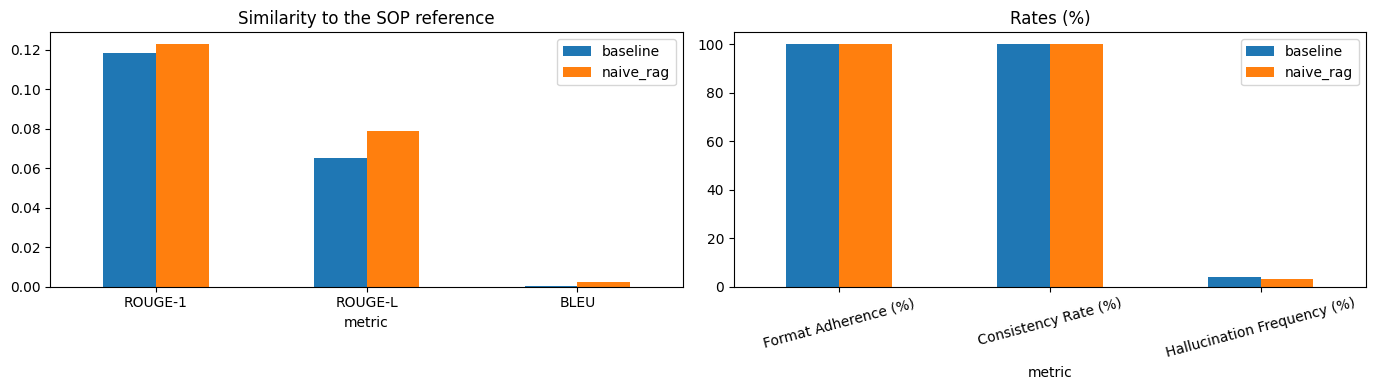

Raw-text retrieval got the wrong SOP for 218 of 390 queries. Most affected intents:
intent
create_account         16
review                 16
place_order            15
delivery_options       15
switch_account         13
contact_human_agent    13
get_invoice            12
change_order           12
Name: count, dtype: int64


In [7]:
def pct_change(new, old):
    return np.nan if old == 0 else (new - old) / old * 100

summary = pd.DataFrame([
    ('Format Adherence (%)', fmt_base, fmt_rag),
    ('ROUGE-1', *sim_table.loc['ROUGE-1']),
    ('ROUGE-L', *sim_table.loc['ROUGE-L']),
    ('BLEU', *sim_table.loc['BLEU']),
    ('Consistency Rate (%)', consist_base, consist_rag),
    ('Hallucination Frequency (%)', hall_base, hall_rag),
    ('Retrieval Hit@1 (%)', np.nan, results.naive_retrieval_hit.mean() * 100),
], columns=['metric', 'baseline', 'naive_rag'])
summary['change_pct'] = [pct_change(n, b) for n, b in zip(summary.naive_rag, summary.baseline)]
display(summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
summary.set_index('metric').loc[['ROUGE-1', 'ROUGE-L', 'BLEU'], ['baseline', 'naive_rag']].plot.bar(ax=axes[0], rot=0)
axes[0].set_title('Similarity to the SOP reference')
summary.set_index('metric').loc[['Format Adherence (%)', 'Consistency Rate (%)', 'Hallucination Frequency (%)'],
                                ['baseline', 'naive_rag']].plot.bar(ax=axes[1], rot=15)
axes[1].set_title('Rates (%)')
plt.tight_layout()
plt.savefig('v1_comparison.png', dpi=120)
plt.show()

misses = results[~results.naive_retrieval_hit]
print(f'Raw-text retrieval got the wrong SOP for {len(misses)} of {len(results)} queries. Most affected intents:')
print(misses.intent.value_counts().head(8))

---
## Save Artifacts

In [8]:
results.to_csv('v1_metrics.csv', index=False)
summary.to_csv('v1_summary.csv', index=False)
print(results.shape)

(390, 24)


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify before proceeding to Notebook 6.**

- [ ] ChromaDB reloaded from `./chroma_db/`
- [ ] **3.3.1** Automated testing run across full test set
- [ ] **3.3.2** Format adherence measured
- [ ] **3.3.3** ROUGE/BLEU computed with SOP-grounded references
- [ ] **3.3.4** Output consistency (determinism) verified
- [ ] **3.3.5** Hallucination frequency quantified
- [ ] **3.4.1** Retrieval impact quantified with improvement %
- [ ] **`v1_metrics.csv` saved** ← _Evidence for comparative analysis_

**If any item is unchecked, fix it before moving on.**